#### Pulling the data

In [8]:
from baseband_analysis.core import BBData
from baseband_analysis.dev.Morphology_dev import singlebeam_to_input
import numpy as np
%matplotlib inline

Loading singelebeam file /arc/projects/chime_frb/BaseCat2/beamformed_files/FRB20181209A_22154974_beamformed.h5
Checking if baseband data was already de-smeared..
No DM in tiedbeam_baseband, so continuing on
---------Downsampling---------
Finding the best downsample. The SNr cutoff used is:  12


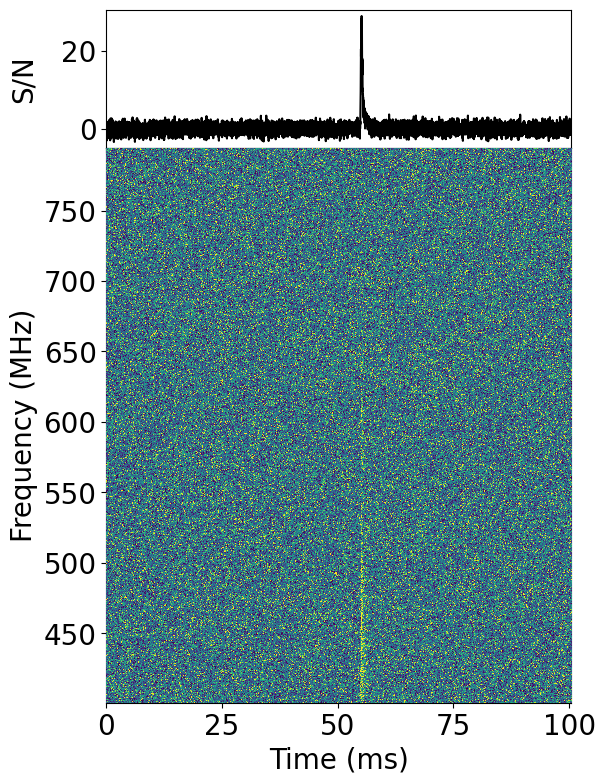

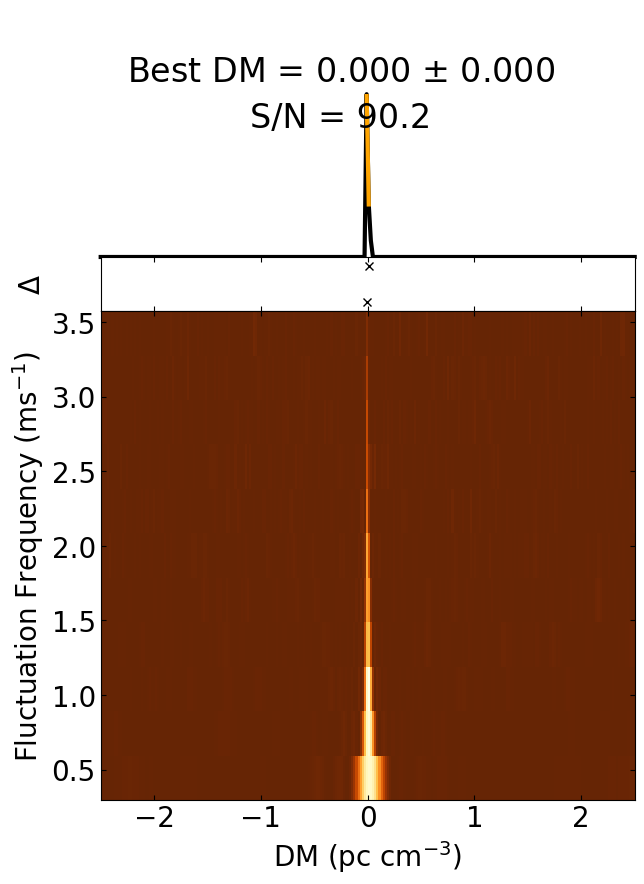

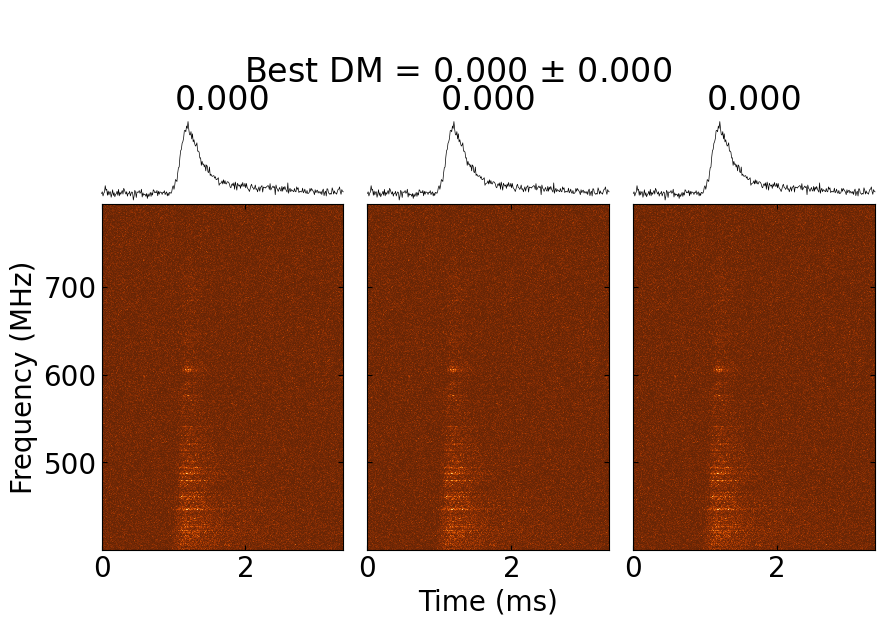

<Figure size 600x900 with 0 Axes>

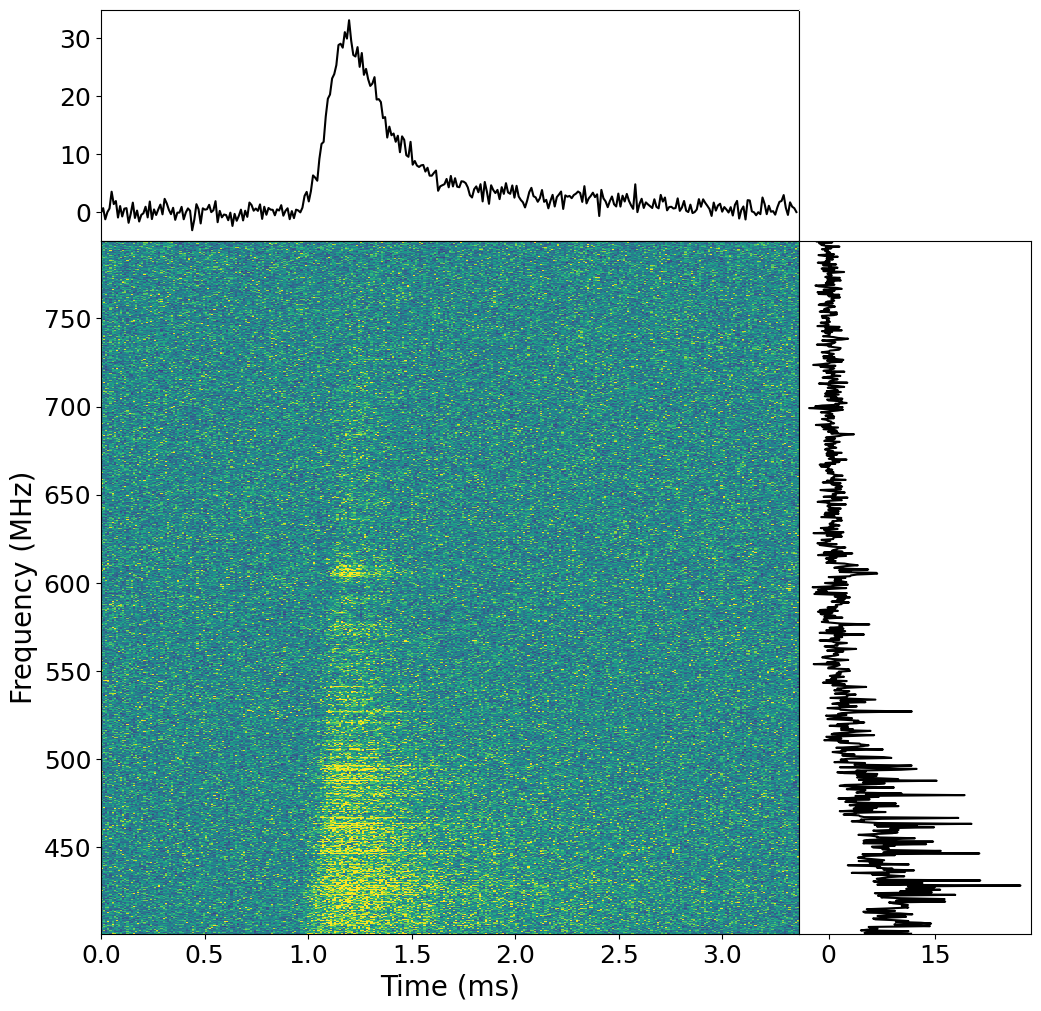

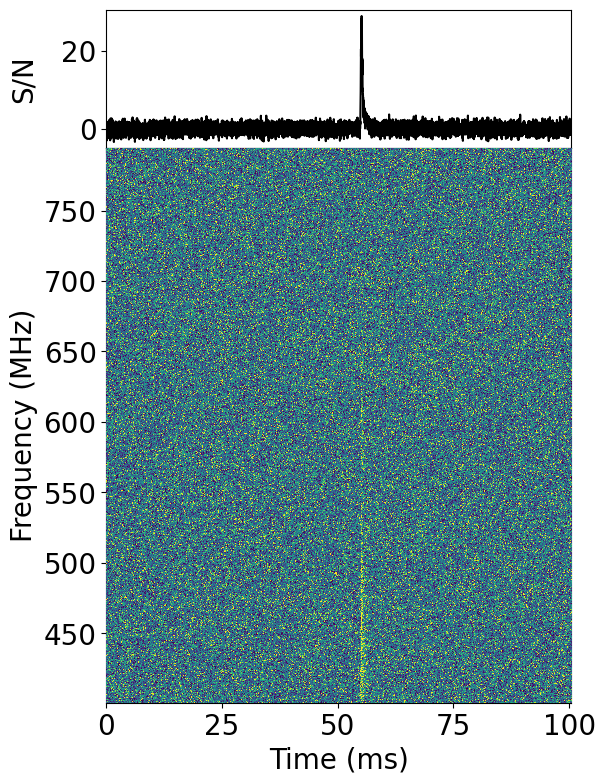

Profile already came in downsampled to:  4
SNR for initial downsampling factor 4: 28.907380497040215
The burst is already bright enough given the snr_cutoff at this downsample
We will use 4 as downsampling factor from now on
---------DM DETERMINATION---------
Running get_snr() to get an estimate on S/N maximizing DM


[2026-08-06 14:58:34,705] INFO Best DM found at 328.5999195049641 pc/cc


The S/N maximizing DM is 328.5999195049641 pc/cc
Grabbing the burst profile
Getting the signal
Running structure maximizing DM script


/opt/pysetup/.venv/lib/python3.11/site-packages/DM_phase.py:590: RankWarning: Polyfit may be poorly conditioned
  p = np.polyfit(dx,y,n,w = w)


The structure maximizing DM is 328.5999195049641 pc/cc +/- 0.0 pc/cc
Running get_snr() again now at the final DM of:  328.5999195049641


/opt/pysetup/baseband_analysis/core/signal.py:106: RuntimeWarning: Mean of empty slice
  if not np.isnan(np.nanmean(power_in[-1], axis=0)).any():
/opt/pysetup/baseband_analysis/core/flagging.py:103: RuntimeWarning: Mean of empty slice
  spect = get_spect(np.nanmean(power_beam, axis=-1), thres=thres_mean)
/opt/pysetup/.venv/lib/python3.11/site-packages/numpy/lib/nanfunctions.py:1879: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


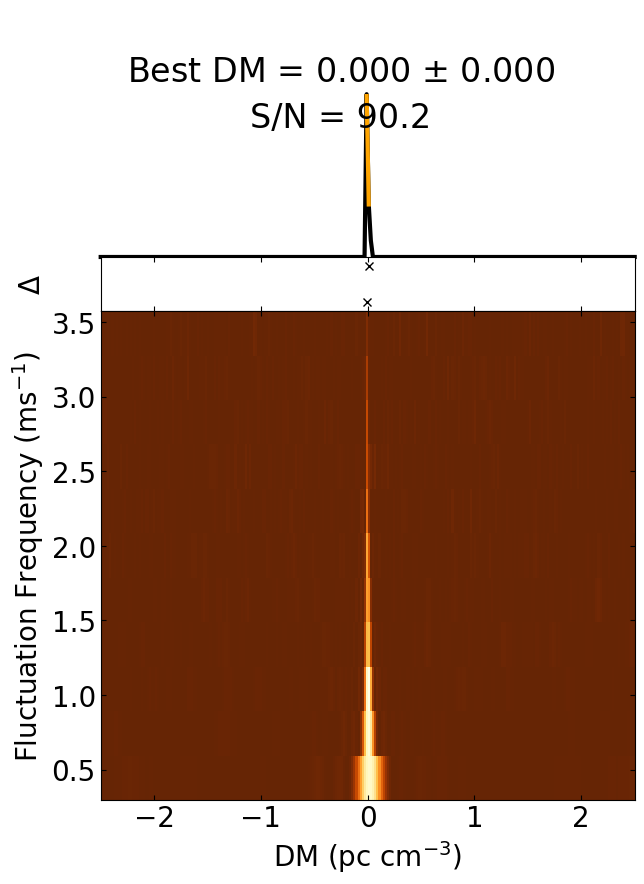

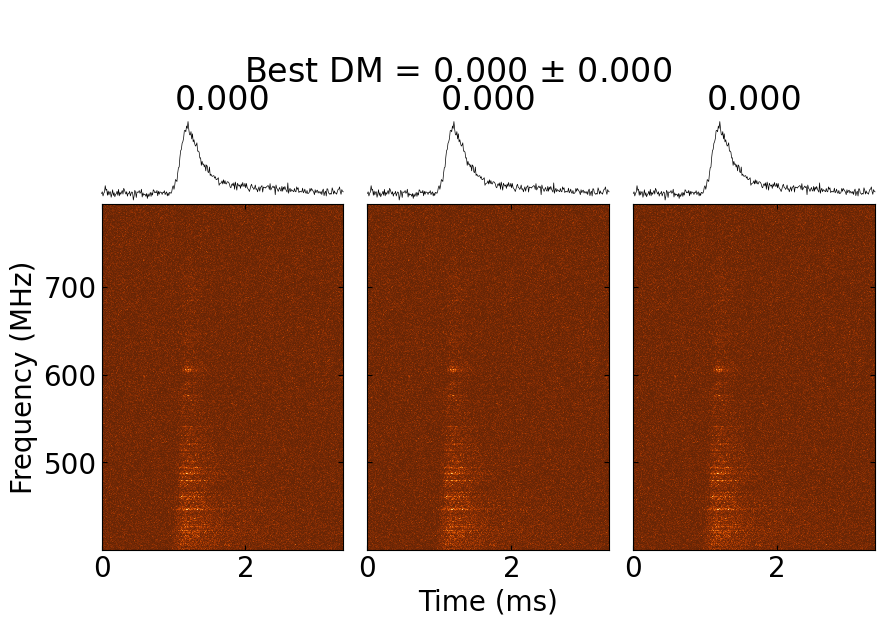

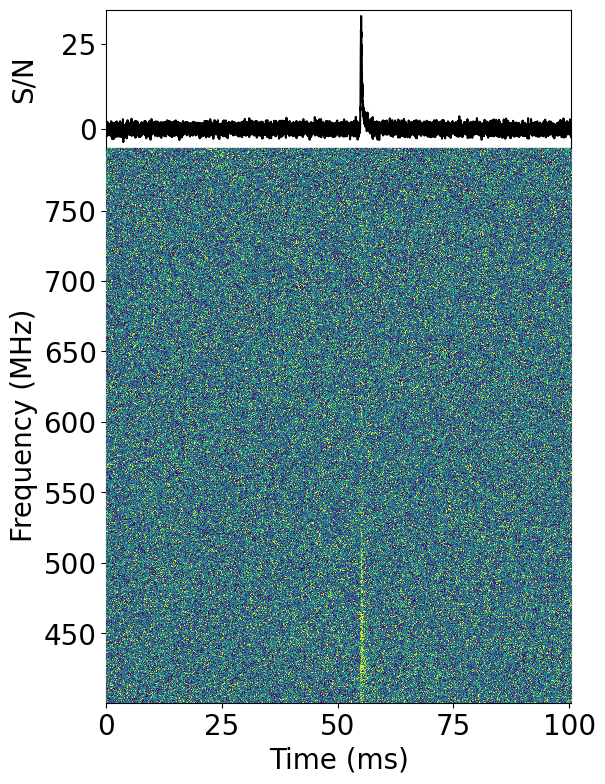

Getting the signal
Plotting a waterfall of the power


<Figure size 1000x1000 with 0 Axes>

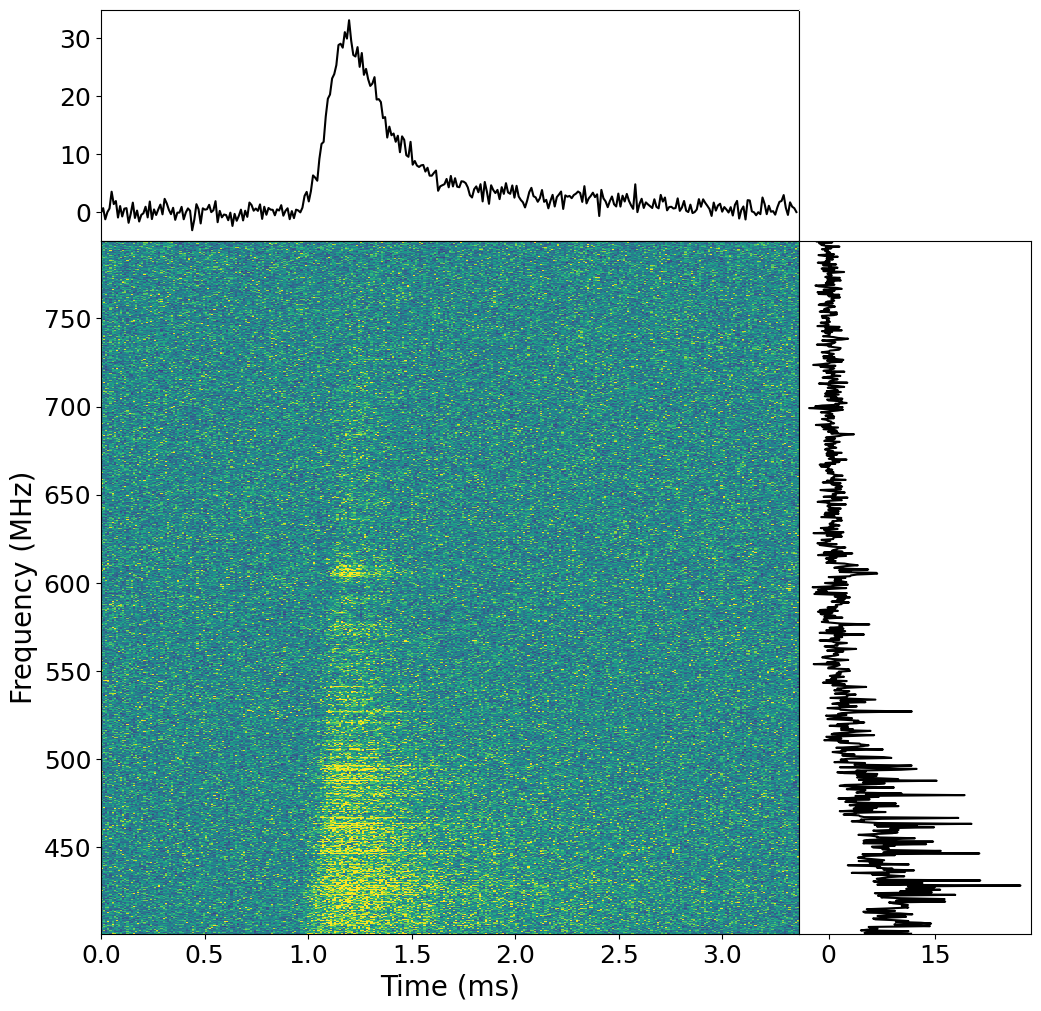

In [9]:
# event ID 22154974
# baseband file path:arc/projects/chime_frb/BaseCat2/beamformed_files/FRB20181209A_22154974_beamformed.h5

file = "/arc/projects/chime_frb/BaseCat2/beamformed_files/FRB20181209A_22154974_beamformed.h5"
print("Loading singelebeam file {}".format(file))
data = BBData.from_file(file)

data, freq_id, freq, power, valid_channels, DM, DM_err, downsampling_factor, profile, t_res, start, full_power = singlebeam_to_input(file,
                                                                                                                                     downsample = 4, # downsampling in time
                                                                                                                                     fit_DM = True, # getting a structure max DM 
                                                                                                                                     diagnostic_plots = True,
                                                                                                                                     snr_cutoff = 12,
                                                                                                                                     )



In [6]:
n_time = power.shape[1]
time = start + t_res * np.arange(n_time)

In [7]:
np.savez('event_22154974_BB.npz', power=power, freq=freq, time=time)
# or np.savez_compressed(...) if power is large and you want smaller files